# A spatial field and one path per facility: Poisson counts of emission events with NUTS and SVI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/ssm_spatial_hierarchical.ipynb)

Examples [1](ssm_one_site.ipynb), [2](ssm_hierarchical_sites.ipynb) and [3](ssm_shared_plus_site.ipynb) all had Gaussian observations, so the Kalman filter integrated every latent path out and NUTS only ever saw a handful of hyperparameters. Here the observations are counts. We take a set of oil and gas facilities at known locations in one basin, and for each facility the daily number of methane emission events that its monitoring flagged. The log of a facility's event rate is a spatial facility effect, a GP over the facility locations (facilities close to each other share operators, equipment and gas composition), plus a temporal path of its own, a Markov GP over the days (maintenance, liquids unloading and other episodes that last days to weeks). With a Poisson likelihood there is no Kalman marginal, so the paths have to be sampled. We sample them through whitened innovations with `markov_gp_innovations_sample`, inside a `numpyro.plate` over the facilities, and fit the same model with NUTS and with SVI.

**pyrox-ssm capability shown:** `markov_gp_innovations_sample`, which registers standard normal innovations as one sample site `f"{name}_eps"` and the Markov-GP path built from them as a deterministic site `name`, with one independent path per index of an enclosing `numpyro.plate`. The path is the SDE run forward by a `lax.scan`, so the latent paths are sampled in a whitened (non-centred) form, which is the geometry NUTS needs. **Cost:** every log-density evaluation is one scan over the $T$ days per facility, $\mathcal{O}(N_\Omega T D_x^3)$, against the $\mathcal{O}(T^3)$ Cholesky factor (and the $T \times T$ kernel matrix) of the dense `markov_gp_sample`. We measure both, per gradient and per NUTS draw, in section 8.

**What you'll learn:**

1. How to write a spatio-temporal Poisson model as a plain NumPyro function that composes a `pyrox_gp` kernel over the facility locations with a `pyrox_ssm` path over the days.
2. How to fit it with NUTS and with SVI, and how their posteriors of the five hyperparameters compare with the truth.
3. How to read the latent rates, the predictions on withheld days and a short forecast, and a map of the spatial facility effect, off the posterior draws.
4. What the whitened path costs against the dense one, per gradient and per NUTS draw.

The Matérn-3/2 SDE and its state-space form are explained in [Example 1](ssm_one_site.ipynb), and the plate over sites and the non-centred draws in [Example 2](ssm_hierarchical_sites.ipynb). We reuse both here without deriving them again.

## Why `pyrox_gp` and `pyrox_ssm` appear together

The spatial effect is an ordinary GP over a few points in $\mathbb{R}^2$, which is what `pyrox_gp` provides: a Matérn kernel whose hyperparameters carry priors (`Matern` with `set_prior`), a `GPPrior` over the facility coordinates and the whitened `gp_sample`. The temporal paths are Markov GPs, which are `pyrox_ssm`. Neither package imports the other. Both depend only on `pyrox` (the bridge), and `pyrox-ssm` is forbidden from importing `pyrox-gp` by its import-guard test (`AGENTS.md`). That rule is about the dependencies between the packages, not about the models people build with them. So a user who imports both and composes them in one NumPyro function, as we do below, is the intended use, and the two packages meet only through NumPyro's sample sites.

## Background

The basin holds a set $\Omega_y$ of $N_\Omega \equiv N_{\Omega_y} = 8$ facilities. We index them by $n = 1, \ldots, N_\Omega$, as we indexed the stations in Examples 2 and 3, and keep $\mathbf{s}$ for coordinates: facility $n$ sits at $\mathbf{s}_n \in \Omega \subset \mathbb{R}^{2}$ (km), and $\mathbf{S}_y \in \mathbb{R}^{N_\Omega \times 2}$ stacks the $\mathbf{s}_n$ as rows. The days $t_k$, $k = 1, \ldots, T$, form the grid $\mathcal{T}_x$ of $T \equiv N_{\mathcal{T}_x}$ days on which the latent paths live, and $y_{n,k} \in \{0, 1, 2, \ldots\}$ is the number of events at facility $n$ on day $t_k$, observed when the mask $o_{n,k} \in \{0, 1\}$ is 1. The counts are Poisson with a log-linear rate,

$$y_{n,k} \sim \mathrm{Poisson}(\rho_{n,k})$$

$$\log \rho_{n,k} = c + g(\mathbf{s}_n) + f_n(t_k)$$

$$g \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(\mathbf{s}, \mathbf{s}'; \sigma_g^2, \ell_g))$$

$$f_n \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_f^2, \ell))$$

where $\rho_{n,k} \in \mathbb{R}_{>0}$ is the event rate (events per day), $c \in \mathbb{R}$ is the intercept (the log rate of a typical facility), $g$ is the spatial facility effect and $f_n$ is facility $n$'s temporal path. The paths $f_1, \ldots, f_{N_\Omega}$ are independent of each other and of $g$, and they share one kernel, as the local paths of Example 3 did. The kernel variances $\sigma_g^2$ and $\sigma_f^2$ (in log-rate units squared), the spatial lengthscale $\ell_g$ (km) and the temporal lengthscale $\ell$ (days) are all in $\mathbb{R}_{>0}$, so $\boldsymbol{\theta} = (c, \sigma_g^2, \ell_g, \sigma_f^2, \ell) \in \mathbb{R}^{5}$. With $\mathbf{Y} \in \{0, 1, 2, \ldots\}^{N_\Omega \times T}$ the counts and $\boldsymbol{\rho} \in \mathbb{R}_{>0}^{N_\Omega \times T}$ the rates, the log likelihood keeps only the observed entries,

$$\log p(\mathbf{Y} \mid \boldsymbol{\rho}) = \sum_{n=1}^{N_\Omega} \sum_{k=1}^{T} o_{n,k} (y_{n,k} \log \rho_{n,k} - \rho_{n,k} - \log y_{n,k}!)$$

The Poisson likelihood is not Gaussian, so we cannot integrate the latent values out with a Kalman filter as in Examples 1 to 3, and NUTS has to sample them. Sampled directly, the latent values and their hyperparameters form a funnel, as $\boldsymbol{\tau}_\theta$ and $\boldsymbol{\theta}_n$ did in Example 2. So we sample both in a whitened form, with standard normal values that are a priori independent of $\boldsymbol{\theta}$. For the spatial effect at the facilities, $\mathbf{g} = g(\mathbf{S}_y) \in \mathbb{R}^{N_\Omega}$,

$$\mathbf{g} = \mathbf{L}_{SS} \mathbf{z}_g$$

$$\mathbf{z}_g \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{N_\Omega})$$

where $\mathbf{L}_{SS} \in \mathbb{R}^{N_\Omega \times N_\Omega}$ is the lower Cholesky factor of the kernel matrix $\mathbf{K}_{SS} \in \mathbb{R}^{N_\Omega \times N_\Omega}$, $[\mathbf{K}_{SS}]_{nn'} = k_\text{Matérn-3/2}(\mathbf{s}_n, \mathbf{s}_{n'}; \sigma_g^2, \ell_g)$. This is what `pyrox_gp.gp_sample(..., whitened=True)` registers. For the temporal paths we run the Matérn-3/2 SDE of Example 1 forward from standard normal innovations $\mathbf{z}_{n,k} \in \mathbb{R}^{D_x}$, with the state $\mathbf{x}_{n,k} \in \mathbb{R}^{D_x}$ and $D_x = 2$,

$$\mathbf{x}_{n,1} = \mathbf{L}_{x,\infty} \mathbf{z}_{n,1}$$

$$\mathbf{x}_{n,k} = \mathbf{F}_k \mathbf{x}_{n,k-1} + \mathbf{L}_{\eta,k} \mathbf{z}_{n,k}$$

$$f_n(t_k) = \mathbf{H} \mathbf{x}_{n,k}$$

$$\mathbf{z}_{n,k} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{D_x})$$

where $\mathbf{F}_k \in \mathbb{R}^{D_x \times D_x}$ is the transition over $\Delta t_k = t_k - t_{k-1}$, $\mathbf{H} \in \mathbb{R}^{1 \times D_x}$ the measurement row, and $\mathbf{L}_{x,\infty}, \mathbf{L}_{\eta,k} \in \mathbb{R}^{D_x \times D_x}$ the Cholesky factors of the stationary covariance $\boldsymbol{\Sigma}_{x,\infty}$ and of the model noise covariance $\boldsymbol{\Sigma}_{\eta,k} = \boldsymbol{\Sigma}_{x,\infty} - \mathbf{F}_k \boldsymbol{\Sigma}_{x,\infty} \mathbf{F}_k^\top$. The map from the innovations to the path is linear, so the path $\mathbf{f}_n = f_n(t_{1:T}) \in \mathbb{R}^{N_{\mathcal{T}_x}}$ has exactly the prior $\mathcal{N}(\mathbf{0}, \mathbf{K}_{tt})$, with $\mathbf{K}_{tt} \in \mathbb{R}^{T \times T}$ the Matérn-3/2 kernel matrix over the days, but it costs $\mathcal{O}(T D_x^3)$ and never forms $\mathbf{K}_{tt}$. This is `markov_gp_innovations_sample`; `markov_gp_sample` instead samples $\mathbf{f}_n \sim \mathcal{N}(\mathbf{0}, \mathbf{K}_{tt})$ directly, which is centred and needs $\mathbf{K}_{tt}$ and its Cholesky factor on every evaluation. The API calls the $\mathbf{z}_{n,k}$ innovations, which are not the Kalman residuals of the same name. NUTS then samples $\boldsymbol{\theta}$, $\mathbf{z}_g$ and the $N_\Omega T$ innovations $\mathbf{z}_{n,k}$, that is $5 + N_\Omega + N_\Omega T D_x$ unconstrained values.

## Setup

We detect Colab and install `pyrox`, `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when the notebook runs there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time
from functools import partial

import einx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
from numpyro import handlers
from numpyro.diagnostics import summary
from numpyro.infer import MCMC, NUTS, SVI, Predictive, Trace_ELBO, init_to_median
from numpyro.infer.autoguide import AutoNormal
from numpyro.infer.util import log_density
from pyrox_gp import GPPrior, Matern, gp_sample
from pyrox_ssm import (
    MarkovGPPrior,
    MaternSDE,
    markov_gp_from_innovations,
    markov_gp_innovations_sample,
    markov_gp_sample,
)


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p jax,equinox,numpyro,gaussx,pyrox,pyrox_gp,pyrox_ssm,matplotlib",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.6.15
pyrox     : 0.2.1
pyrox_gp  : 0.2.0
pyrox_ssm : 0.1.0
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Eight facilities in one basin

We simulate the model itself, so that we know every true value. The basin is 100 km by 100 km and the eight facilities sit at random locations in it. A typical facility has two events per day ($c = \log 2$). The spatial effect has a variance of 0.5, so the baseline rates of different facilities differ by a factor of about two either way, and it decorrelates over about 30 km. Each facility's path has a variance of 0.4 and decorrelates over about a week. We draw the spatial effect jointly on a 40 by 40 grid of map cells and at the facilities, so that we can score the map in section 7.

The record runs for $T = 80$ days. The facilities report on days 0 to 64, and days 65 to 79 are left for a forecast. On each reporting day a facility's monitoring is down with probability 0.1, and facility 3 has a 15-day outage from day 40. A day without monitoring is a count we never see, so its mask entry is 0, and we keep its true count to score the predictions.

In [4]:
# Shapes: N_Ω = 8 facilities; T = 80 days; M = 1,600 map cells; D_x = 2

truth = {
    "intercept": float(jnp.log(2.0)),  # two events per day at a typical facility
    "spatial.variance": 0.5,
    "spatial.lengthscale": 30.0,  # km
    "temporal_variance": 0.4,
    "temporal_lengthscale": 7.0,  # days
}
N_FACILITIES = 8
N_DAYS = 80
LAST_REPORT = 65  # facilities report on days 0, …, 64; the rest is a forecast
BASIN_KM = 100.0
N_SIDE = 40

key_s, key_g, key_f, key_y, key_gap = jr.split(jr.PRNGKey(2027), 5)
# s_n, uniform over the basin
coords = BASIN_KM * jr.uniform(key_s, (N_FACILITIES, 2))  # → (N_Ω, 2)
# t_k, days since the start of the record
days = jnp.arange(N_DAYS, dtype=jnp.float64)  # → (T,)

# the map cells, east varying fastest
axis_km = jnp.linspace(0.0, BASIN_KM, N_SIDE)  # → (N_SIDE,)
east = einx.id("i -> (j i)", axis_km, j=N_SIDE)  # → (M,)
north = einx.id("j -> (j i)", axis_km, i=N_SIDE)  # → (M,)
map_coords = einx.id("m, m -> m (1 + 1)", east, north)  # → (M, 2)
n_cells = map_coords.shape[0]

# today (pyrox_gp)
# k_Matérn-3/2(s, s'; σ_g², ℓ_g) with the true hyperparameters
spatial_kernel_true = Matern(
    nu=1.5,
    init_variance=truth["spatial.variance"],
    init_lengthscale=truth["spatial.lengthscale"],
    pyrox_name="spatial",
)
# map cells first, then the facilities
field_points = jnp.concatenate([map_coords, coords])  # → (M + N_Ω, 2)
# today (pyrox_gp)
# g(s) on the map cells and at the facilities, one joint draw
field_true = GPPrior(spatial_kernel_true, field_points).sample(key_g)  # → (M + N_Ω,)
g_map_true = field_true[:n_cells]  # → (M,)
g_true = field_true[n_cells:]  # → (N_Ω,)

# today (pyrox_ssm)
# k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE
temporal_sde_true = MaternSDE(
    truth["temporal_variance"], truth["temporal_lengthscale"], order=1
)
# today (pyrox_ssm)
temporal_prior_true = MarkovGPPrior(temporal_sde_true, days)
# z_n,k ~ 𝒩(0, I_D_x)
innovations = jr.normal(key_f, (N_FACILITIES, N_DAYS, 2))  # → (N_Ω, T, D_x)
# today (pyrox_ssm)
# f_n(t_k), one path per facility from its own innovations
f_true = markov_gp_from_innovations(temporal_prior_true, innovations)  # → (N_Ω, T)

# c + g(s_n), the baseline log rate of each facility
baseline_true = truth["intercept"] + g_true  # → (N_Ω,)
# log ρ_n,k = c + g(s_n) + f_n(t_k)
log_rate_true = einx.add("n, n k -> n k", baseline_true, f_true)  # → (N_Ω, T)
rate_true = jnp.exp(log_rate_true)  # → (N_Ω, T)
# y_n,k ~ Poisson(ρ_n,k), on every day
counts_true = jr.poisson(key_y, rate_true)  # → (N_Ω, T)

reporting = days < LAST_REPORT  # → (T,) bool
# monitoring down at random on 10 % of the facility days
downtime = jr.uniform(key_gap, (N_FACILITIES, N_DAYS)) < 0.1  # → (N_Ω, T) bool
outage = jnp.zeros((N_FACILITIES, N_DAYS), dtype=bool)  # → (N_Ω, T) bool
outage = outage.at[2, 40:55].set(True)
# o_n,k = 1 on a reporting day with the monitoring up
mask = einx.logical_and("k, n k -> n k", reporting, ~downtime & ~outage)
# what the operator's file holds
counts = jnp.where(mask, counts_true, 0)  # → (N_Ω, T)

print(
    f"{'facility':<10}{'east km':>9}{'north km':>10}"
    f"{'g(s_n)':>9}{'mean ρ':>9}{'days':>6}"
)
for n in range(N_FACILITIES):
    print(
        f"{n + 1:<10}{float(coords[n, 0]):>9.1f}{float(coords[n, 1]):>10.1f}"
        f"{float(g_true[n]):>9.2f}{float(rate_true[n].mean()):>9.2f}"
        f"{int(mask[n].sum()):>6}"
    )
print(f"observed facility days: {int(mask.sum())} of {N_FACILITIES * LAST_REPORT}")
print(f"largest daily count: {int(counts_true.max())}")

facility    east km  north km   g(s_n)   mean ρ  days


1              74.7      48.9     0.09     3.84    57
2              17.0      99.8    -0.83     0.89    59
3              66.1      60.2    -0.86     1.37    45
4              30.6      20.0     0.29     2.64    54
5              46.2      38.6     0.47     4.37    56
6              72.2      53.5    -0.27     1.84    63
7              56.1      86.0    -0.57     1.36    55
8              35.1      12.6    -0.09     2.72    59
observed facility days: 448 of 520
largest daily count: 14


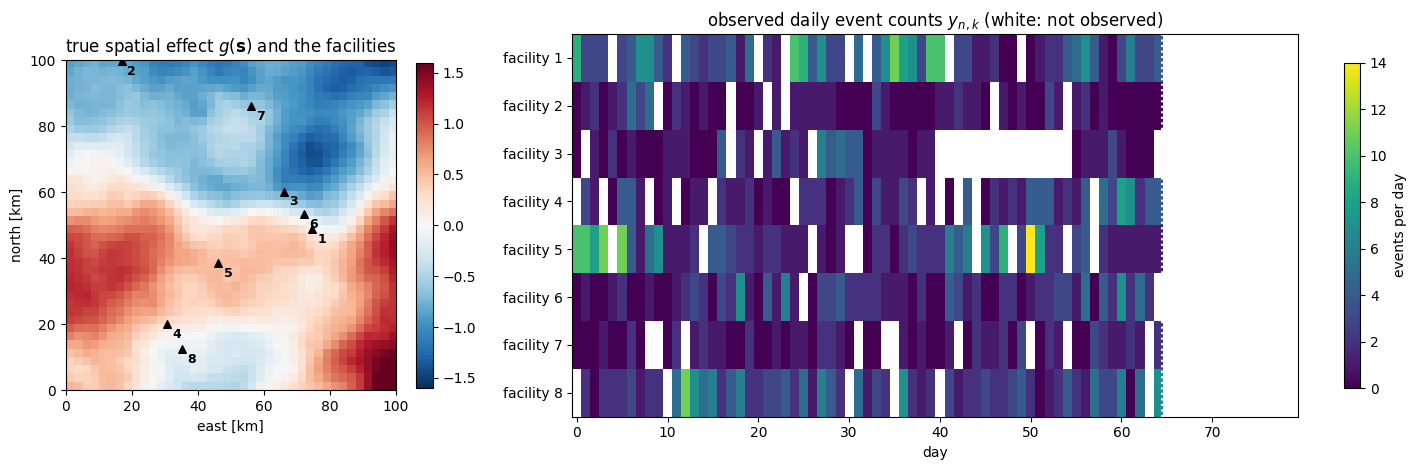

In [5]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 2.2]}
)
ax = axes[0]
im = ax.imshow(
    np.asarray(einx.id("(j i) -> j i", g_map_true, i=N_SIDE)),
    origin="lower",
    extent=(0, BASIN_KM, 0, BASIN_KM),
    cmap="RdBu_r",
    vmin=-1.6,
    vmax=1.6,
)
ax.scatter(coords[:, 0], coords[:, 1], c="k", s=30, marker="^")
for n in range(N_FACILITIES):
    ax.annotate(
        f"{n + 1}",
        np.asarray(coords[n]),
        xytext=(4, -10),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
    )
ax.set_xlabel("east [km]")
ax.set_ylabel("north [km]")
ax.set_title(r"true spatial effect $g(\mathbf{s})$ and the facilities")
fig.colorbar(im, ax=ax, shrink=0.85)

ax = axes[1]
shown = np.where(np.asarray(mask), np.asarray(counts_true), np.nan)
im = ax.imshow(shown, aspect="auto", cmap="viridis", interpolation="nearest")
ax.axvline(LAST_REPORT - 0.5, color="w", ls=":", lw=1.5)
ax.set_yticks(range(N_FACILITIES), [f"facility {n + 1}" for n in range(N_FACILITIES)])
ax.set_xlabel("day")
ax.set_title("observed daily event counts $y_{n,k}$ (white: not observed)")
fig.colorbar(im, ax=ax, shrink=0.85, label="events per day")
plt.tight_layout()
plt.show()

## 2. The model as a plain NumPyro function

The intercept gets $c \sim \mathcal{N}(0, 1)$, so a typical facility has between about 0.14 and 7 events per day (two standard deviations either way). The spatial kernel is `pyrox_gp.Matern(nu=1.5)`, and its hyperparameters get their priors with `set_prior`, so the kernel itself registers them as the sample sites `"spatial.variance"` and `"spatial.lengthscale"`: $\sigma_g^2 \sim \mathrm{LogNormal}(\log 0.5, 1)$ and $\ell_g \sim \mathrm{LogNormal}(\log 30, 0.5)$. Eight facilities say very little about a spatial lengthscale, so its prior states the scale of the basin (between about 10 and 80 km). The temporal kernel gets $\sigma_f^2 \sim \mathrm{LogNormal}(\log 0.5, 1)$ and Example 1's prior for the lengthscale, $\ell \sim \mathrm{LogNormal}(\log 7, 1)$.

Then `gp_sample(..., whitened=True)` draws $\mathbf{z}_g$ as the site `"facility_effect_u"` and records $\mathbf{g}$ as the deterministic `"facility_effect"`. Inside `numpyro.plate("facility", N_Ω)`, `markov_gp_innovations_sample("path", ...)` draws one $(T, D_x)$ block of innovations per facility as the site `"path_eps"` and records the paths as the deterministic `"path"`. The Poisson site `"y"` is masked with `.mask(mask)`, so an unobserved day adds nothing to the log density, and its count, stored as 0, is never read. Its last dimension, the days, is an event dimension (`.to_event(1)`), so the facility plate owns the first one. We also record the rates as a deterministic site `"rate"`, so the posterior samples carry $\rho_{n,k}$ on every day, observed or not.

`sample_path` defaults to `markov_gp_innovations_sample`; section 8 passes `markov_gp_sample` instead, which has the same signature, to fit the dense, centred version of the same model.

In [6]:
def emissions_model(
    coords, days, counts, mask, sample_path=markov_gp_innovations_sample
):
    # Shapes: N_Ω facilities; T days; D_x = 2

    # today (numpyro)
    # c ~ 𝒩(0, 1)
    intercept = numpyro.sample("intercept", dist.Normal(0.0, 1.0))

    # today (pyrox_gp)
    # k_Matérn-3/2(s, s'; σ_g², ℓ_g), whose hyperparameters are sample sites
    spatial_kernel = Matern(nu=1.5, pyrox_name="spatial")
    # today (pyrox)
    # σ_g² ~ LogNormal(log 0.5, 1)
    spatial_kernel.set_prior("variance", dist.LogNormal(jnp.log(0.5), 1.0))
    # today (pyrox)
    # ℓ_g ~ LogNormal(log 30, 0.5)
    spatial_kernel.set_prior("lengthscale", dist.LogNormal(jnp.log(30.0), 0.5))
    # today (pyrox_gp)
    # g ~ 𝒩(0, K_SS) at the facility coordinates S_y
    spatial_prior = GPPrior(spatial_kernel, coords)
    # today (pyrox_gp)
    # g = L_SS z_g, z_g ~ 𝒩(0, I)
    effect = gp_sample("facility_effect", spatial_prior, whitened=True)  # → (N_Ω,)

    # today (numpyro)
    # σ_f² ~ LogNormal(log 0.5, 1)
    temporal_variance = numpyro.sample(
        "temporal_variance", dist.LogNormal(jnp.log(0.5), 1.0)
    )
    # today (numpyro)
    # ℓ ~ LogNormal(log 7, 1)
    temporal_lengthscale = numpyro.sample(
        "temporal_lengthscale", dist.LogNormal(jnp.log(7.0), 1.0)
    )
    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE, pooled over the facilities
    temporal_sde = MaternSDE(temporal_variance, temporal_lengthscale, order=1)
    # today (pyrox_ssm)
    temporal_prior = MarkovGPPrior(temporal_sde, days)

    # c + g(s_n)
    baseline = intercept + effect  # → (N_Ω,)
    # today (numpyro): one path and one row of counts per facility
    with numpyro.plate("facility", coords.shape[0]):
        # today (pyrox_ssm)
        # f_n(t_k) = H x_n,k with x_n,k = F_k x_n,k−1 + L_η,k z_n,k
        path = sample_path("path", temporal_prior)  # → (N_Ω, T)
        # log ρ_n,k = c + g(s_n) + f_n(t_k)
        log_rate = einx.add("n, n k -> n k", baseline, path)  # → (N_Ω, T)
        # today (numpyro)
        # ρ_n,k, recorded on every day
        rate = numpyro.deterministic("rate", jnp.exp(log_rate))  # → (N_Ω, T)
        # today (numpyro)
        # y_n,k ~ Poisson(ρ_n,k) where o_n,k = 1
        numpyro.sample("y", dist.Poisson(rate).mask(mask).to_event(1), obs=counts)


def site_kind(site):
    """A short label for a trace site: plate, deterministic or its family."""
    if site["type"] != "sample":
        return site["type"]
    fn = site["fn"]
    while isinstance(fn, (dist.ExpandedDistribution, dist.Independent)):
        fn = fn.base_dist
    if isinstance(fn, dist.MaskedDistribution):
        fn = fn.base_dist
    return type(fn).__name__


# today (numpyro)
seeded_model = handlers.seed(emissions_model, rng_seed=0)
# today (numpyro)
trace = handlers.trace(seeded_model).get_trace(coords, days, counts, mask)
for name, site in trace.items():
    shape = tuple(jnp.shape(site["value"]))
    print(f"site {name!r:24} {site_kind(site):<14} value shape={shape}")
n_latent = sum(
    int(np.prod(jnp.shape(site["value"])))
    for site in trace.values()
    if site["type"] == "sample" and not site["is_observed"]
)
print(f"unconstrained values for NUTS: {n_latent}")

site 'intercept'              Normal         value shape=()
site 'spatial.variance'       LogNormal      value shape=()
site 'spatial.lengthscale'    LogNormal      value shape=()
site 'facility_effect_u'      Normal         value shape=(8,)
site 'facility_effect'        deterministic  value shape=(8,)
site 'temporal_variance'      LogNormal      value shape=()
site 'temporal_lengthscale'   LogNormal      value shape=()
site 'facility'               plate          value shape=(8,)
site 'path_eps'               Normal         value shape=(8, 80, 2)
site 'path'                   deterministic  value shape=(8, 80)
site 'rate'                   deterministic  value shape=(8, 80)
site 'y'                      Poisson        value shape=(8, 80)
unconstrained values for NUTS: 1293


So the trace holds the five scalar sample sites of $\boldsymbol{\theta}$ (two of them registered by the `pyrox_gp` kernel under its scope `"spatial"`), the whitened spatial values `"facility_effect_u"`, the innovations `"path_eps"` with one $(T, D_x)$ block per facility, three deterministic sites and the masked Poisson site. Unlike Examples 1 to 3, NUTS now sees every latent value, $5 + N_\Omega + N_\Omega T D_x = 1{,}293$ of them.

## 3. NUTS

We run two chains of 150 draws after 150 warm-up steps, started at the prior medians with `init_to_median`, which puts every whitened value at 0. A dense mass matrix over all 1,293 values would have about 1.7 million entries to adapt. However, only a few of them are strongly correlated in the posterior: the intercept trades off against the mean of the facility effects (a higher $c$ with lower $g(\mathbf{s}_n)$ gives the same rates), and $\sigma_g^2$ against the scale of $\mathbf{z}_g$. So we give the 13 values outside the paths ($\boldsymbol{\theta}$ and $\mathbf{z}_g$) one dense $13 \times 13$ block of the mass matrix, with `dense_mass=[(...)]`, and keep the 1,280 innovations on the diagonal, where their unit prior scale suits it. The chains run one after the other with `chain_method="sequential"`, as in Example 1. The wall-clock time includes JIT compilation. We print the summary for the five hyperparameters, and for the spatial effects and the rates on the observed facility days only the worst $\hat{R}$ and the smallest effective sample size.

In [7]:
# Shapes: D = 1,293 sampled values; 2 chains × 150 = 300 posterior draws

hyper_names = list(truth)

# the 13 values outside the paths share one dense block of the mass matrix
dense_block = [(*hyper_names, "facility_effect_u")]
# today (numpyro)
nuts_kernel = NUTS(
    emissions_model, init_strategy=init_to_median, dense_mass=dense_block
)
# today (numpyro)
nuts = MCMC(
    nuts_kernel,
    num_warmup=150,
    num_samples=150,
    num_chains=2,
    chain_method="sequential",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
# 300 draws from p(θ, z_g, Z ∣ Y)
nuts.run(jr.PRNGKey(1), coords, days, counts, mask, extra_fields=("num_steps",))
jax.block_until_ready(nuts.get_samples())
nuts_seconds = time.perf_counter() - t0
nuts_samples = nuts.get_samples()  # → {name: (300, …)}
by_chain = nuts.get_samples(group_by_chain=True)  # → {name: (2, 150, …)}
# today (numpyro)
numpyro.diagnostics.print_summary({k: by_chain[k] for k in hyper_names})
# the spatial effects and the rates on the observed facility days
rate_draws = np.asarray(by_chain["rate"])  # → (2, 150, N_Ω, T)
observed_rates = rate_draws[:, :, np.asarray(mask)]  # → (2, 150, N_obs)
latent_summary = summary(
    {"facility_effect": by_chain["facility_effect"], "rate": observed_rates}
)
worst_r_hat = max(float(np.max(s["r_hat"])) for s in latent_summary.values())
fewest_n_eff = min(float(np.min(s["n_eff"])) for s in latent_summary.values())
extra_fields = nuts.get_extra_fields()
n_div = int(extra_fields["diverging"].sum())  # → ()
n_grad = int(extra_fields["num_steps"].sum())  # → ()
print(
    f"g(s_n) and the observed-day rates: largest r_hat = {worst_r_hat:.3f}, "
    f"smallest n_eff = {fewest_n_eff:.0f}"
)
print(
    f"NUTS wall-clock: {nuts_seconds:.1f} s for 2 chains x 300 iterations, "
    f"{n_div} divergences"
)
print(
    f"leapfrog steps after warm-up: {n_grad}, {n_grad / 300:.1f} per draw "
    f"(one scan over {N_DAYS} days per facility and its gradient each)"
)


                            mean       std    median      5.0%     95.0%     n_eff     r_hat
             intercept      0.30      0.40      0.32     -0.26      1.00    141.19      1.00
      spatial.variance      0.56      0.38      0.45      0.09      1.04    177.24      1.01
   spatial.lengthscale     36.90     19.26     33.13     11.06     63.99    293.37      0.99
     temporal_variance      0.39      0.10      0.38      0.25      0.56     96.91      1.01
  temporal_lengthscale      6.55      1.77      6.34      3.85      9.07    100.38      0.99



g(s_n) and the observed-day rates: largest r_hat = 1.024, smallest n_eff = 48
NUTS wall-clock: 83.4 s for 2 chains x 300 iterations, 1 divergences
leapfrog steps after warm-up: 18899, 63.0 per draw (one scan over 80 days per facility and its gradient each)


We get one divergence in 300 draws, and every $\hat{R}$ of the five hyperparameters is between 0.99 and 1.01. The smallest effective sample size among them is 97, for $\sigma_f^2$. Over the spatial effects and the 448 rates of the observed facility days the largest $\hat{R}$ is 1.024 and the smallest effective sample size 48, so the chains are usable but not long. After warm-up every draw took exactly 63 leapfrog steps, a tree of depth 6, and the whole run took 83.4 s.

## 4. SVI with a mean-field guide

With 1,293 latent values a full-rank Gaussian guide, as in Example 1, would have about a million covariance parameters. In the whitened coordinates, however, the prior is a standard normal with no correlations at all, which is what makes a mean-field guide workable for the latent values, and the reason `gp_sample` has its `whitened=True` mode. Whether it is good enough for the hyperparameters we check against NUTS in section 5. `AutoNormal` puts an independent Gaussian on every unconstrained value, the five hyperparameters included, and we start it at the prior medians. The guide is $q(\boldsymbol{\theta}, \mathbf{z}_g, \mathbf{Z}; \boldsymbol{\nu})$ with $\boldsymbol{\nu}$ its means and scales, and SVI minimises $\mathcal{L}_\text{ELBO}(\boldsymbol{\nu}) = -\mathrm{ELBO}$. `Predictive` with the guide then gives the deterministic sites, the paths and the rates, for 1,000 guide draws.

SVI wall-clock: 14.7 s for 3000 steps x 2 particles
final negative ELBO (mean of last 200 steps): 835.5


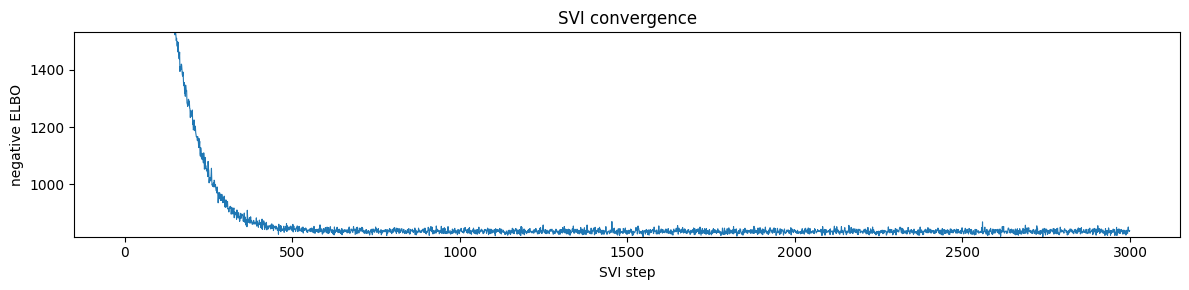

In [8]:
# Shapes: D = 1,293 values; 2 D variational parameters; 1,000 guide draws

# today (numpyro)
# q(θ, z_g, Z; ν), an independent Gaussian on every unconstrained value
guide = AutoNormal(emissions_model, init_loc_fn=init_to_median)
# today (optax)
optimizer = optax.adam(0.01)
# today (numpyro)
# ℒ_ELBO(ν) = −ELBO, a Monte Carlo estimate from 2 particles
elbo = Trace_ELBO(num_particles=2)
# today (numpyro)
svi = SVI(emissions_model, guide, optimizer, elbo)
t0 = time.perf_counter()
# today (numpyro)
# ν⋆ = argmin_ν ℒ_ELBO(ν), 3000 Adam steps
svi_result = svi.run(
    jr.PRNGKey(3), 3000, coords, days, counts, mask, progress_bar=False
)
jax.block_until_ready(svi_result.params)
svi_seconds = time.perf_counter() - t0
# today (numpyro)
guide_predictive = Predictive(
    emissions_model,
    guide=guide,
    params=svi_result.params,
    num_samples=1000,
    return_sites=[*hyper_names, "facility_effect", "rate"],
)
# today (numpyro)
# 1,000 draws from q(·; ν⋆), with the deterministic sites
svi_samples = guide_predictive(  # → {name: (1000, …)}
    jr.PRNGKey(4), coords, days, counts, mask
)
final_loss = float(svi_result.losses[-200:].mean())  # → ()
print(f"SVI wall-clock: {svi_seconds:.1f} s for 3000 steps x 2 particles")
print(f"final negative ELBO (mean of last 200 steps): {final_loss:.1f}")

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.asarray(svi_result.losses), "C0", lw=0.8)
ax.set_ylim(np.percentile(np.asarray(svi_result.losses), [0, 95]))
ax.set_xlabel("SVI step")
ax.set_ylabel("negative ELBO")
ax.set_title("SVI convergence")
plt.tight_layout()
plt.show()

## 5. The hyperparameters against the truth

For each hyperparameter we print the posterior mean, standard deviation and 90 % interval from NUTS and from SVI, next to the value we simulated the data with.

In [9]:
header = (
    f"{'parameter':<22}{'truth':>8}  {'NUTS mean ± sd':>18}  "
    f"{'NUTS 90% interval':>22}  {'SVI mean ± sd':>18}  {'SVI 90% interval':>22}"
)
print(header)
for k in hyper_names:
    row = f"{k:<22}{truth[k]:>8.2f}"
    for s in (nuts_samples, svi_samples):
        v = np.asarray(s[k])
        lo, hi = np.percentile(v, [5, 95])
        inside = "in" if lo <= truth[k] <= hi else "out"
        row += (
            f"  {v.mean():>9.3f} ± {v.std():<6.3f}  "
            f"[{lo:>7.3f}, {hi:>7.3f}] {inside:>3}"
        )
    print(row)

parameter                truth      NUTS mean ± sd       NUTS 90% interval       SVI mean ± sd        SVI 90% interval
intercept                 0.69      0.298 ± 0.397   [ -0.369,   0.902]  in      0.493 ± 0.034   [  0.438,   0.547] out
spatial.variance          0.50      0.560 ± 0.375   [  0.150,   1.295]  in      0.459 ± 0.063   [  0.362,   0.567]  in
spatial.lengthscale      30.00     36.905 ± 19.224  [ 13.487,  71.406]  in     22.432 ± 3.403   [ 17.281,  28.204] out
temporal_variance         0.40      0.394 ± 0.104   [  0.260,   0.577]  in      0.123 ± 0.018   [  0.095,   0.155] out
temporal_lengthscale      7.00      6.547 ± 1.768   [  4.142,   9.561]  in      2.940 ± 0.271   [  2.520,   3.412] out


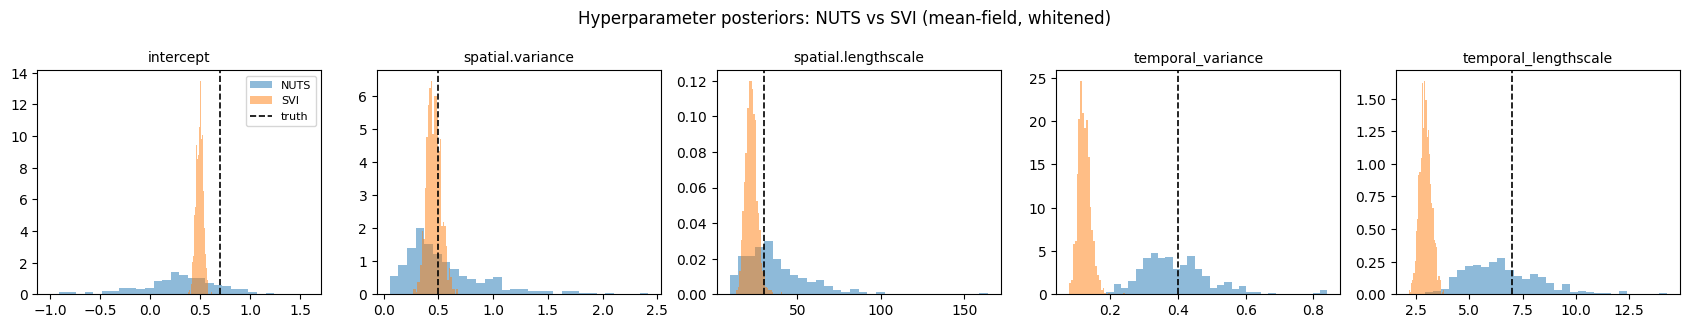

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.3))
for ax, k in zip(axes, hyper_names, strict=True):
    for s, label, color in ((nuts_samples, "NUTS", "C0"), (svi_samples, "SVI", "C1")):
        ax.hist(
            np.asarray(s[k]), bins=30, density=True, alpha=0.5, color=color, label=label
        )
    ax.axvline(truth[k], color="k", ls="--", lw=1.2, label="truth")
    ax.set_title(k, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Hyperparameter posteriors: NUTS vs SVI (mean-field, whitened)")
plt.tight_layout()
plt.show()

NUTS has all five true values inside its 90 % intervals. The temporal kernel is the best determined, with $\sigma_f^2$ at 0.394 ± 0.104 (true 0.4) and $\ell$ at 6.55 ± 1.77 days (true 7), because each of the eight facilities contributes its own path to it. The spatial kernel rests on only eight points. So $\sigma_g^2$ is uncertain (0.56 ± 0.38, true 0.5) and the 90 % interval of $\ell_g$ runs from 13.5 to 71.4 km, which is mostly the prior. The intercept, 0.30 ± 0.40 against $\log 2 = 0.69$, is wide because it trades off against the mean of the eight facility effects, which section 7 shows.

SVI does much worse on the hyperparameters. Only $\sigma_g^2$ falls inside its 90 % interval. The temporal kernel comes out at under a third of the true variance ($\sigma_f^2$ = 0.123 ± 0.018) and less than half the true lengthscale ($\ell$ = 2.94 ± 0.27 days), with standard deviations about six times smaller than those of NUTS. The mean-field guide makes every value independent of every other, whereas in the posterior the temporal hyperparameters and the 1,280 innovations depend strongly on each other (the same path can come from a larger $\sigma_f^2$ with smaller innovations, or the other way round). So we take the NUTS posterior as the reference here, and SVI as a fast approximation of the latent rates, which we check next.

## 6. Latent rates and predictions at every facility

Every posterior draw $e \in \mathcal{E}$ carries the whole rate field, $\rho_{n,k}^{(e)} = \exp(c^{(e)} + g^{(e)}(\mathbf{s}_n) + f_n^{(e)}(t_k))$, on every day of the grid. The paths were sampled on all $T$ days, and the mask only kept the unobserved days out of the likelihood, so the withheld days and the forecast need no extra step: they are the days on which the posterior of the path is informed by its neighbours (or, in the forecast, by nothing but the prior after the last observation). The rate is a nonlinear function of the latent values, so we summarise it with the posterior mean $\bar{\rho}_{n,k} = \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} \rho_{n,k}^{(e)}$ and the 2.5 % and 97.5 % quantiles over the draws, the 95 % band. For a new count we draw $y_{n,k}^{(e)} \sim \mathrm{Poisson}(\rho_{n,k}^{(e)})$ once per draw and take the same quantiles, which gives the 95 % predictive interval of the count.

In [11]:
# Shapes: N_Ω = 8 facilities; T = 80 days; N_E = 300 NUTS or 1,000 SVI draws


def rate_summary(rate_draws, key):
    """Mean and 95 % bands of ρ and of a new count y, over the draw axis."""
    # ρ̄_n,k = (1/N_E) ∑ₑ ρ_n,k⁽ᵉ⁾
    mean = einx.mean("member n k -> n k", rate_draws)  # → (N_Ω, T)
    # the 2.5 % and 97.5 % quantiles of ρ_n,k⁽ᵉ⁾ over the draws
    lo, hi = np.percentile(np.asarray(rate_draws), [2.5, 97.5], axis=0)
    # y_n,k⁽ᵉ⁾ ~ Poisson(ρ_n,k⁽ᵉ⁾), one new count per draw
    new_counts = jr.poisson(key, rate_draws)  # → (N_E, N_Ω, T)
    # the same quantiles of the new counts
    y_lo, y_hi = np.percentile(np.asarray(new_counts), [2.5, 97.5], axis=0)
    return {"mean": mean, "lo": lo, "hi": hi, "y_lo": y_lo, "y_hi": y_hi}


nuts_rates = rate_summary(nuts_samples["rate"], jr.PRNGKey(5))  # → {name: (N_Ω, T)}
svi_rates = rate_summary(svi_samples["rate"], jr.PRNGKey(6))  # → {name: (N_Ω, T)}

Each panel below is one facility. The blue band is the NUTS 95 % band of the latent rate $\rho_{n,k}$ with its posterior mean, and the dashed green lines are the SVI band. The thin black line is the true rate, the orange dots are the observed counts and the red crosses the counts on the days the monitoring was down (including the forecast after the dotted line), which the model never saw. Facility 3's outage is shaded.

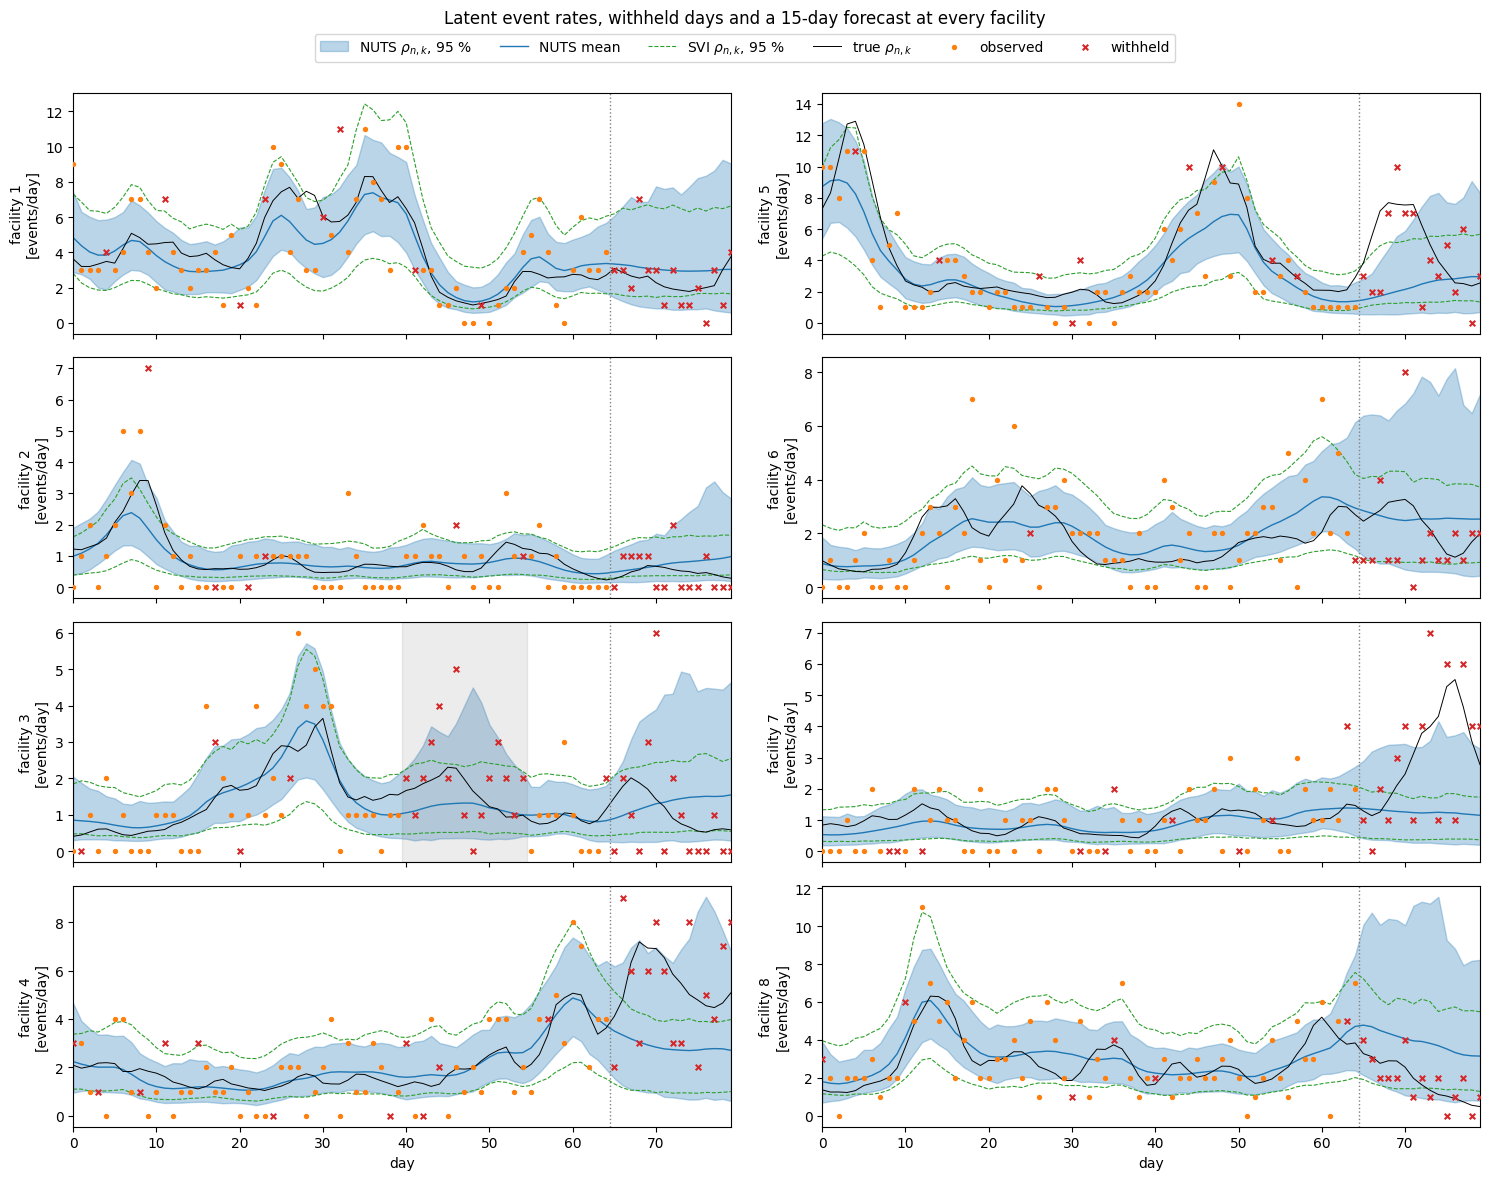

In [12]:
t_grid = np.asarray(days)  # → (T,)
withheld = ~np.asarray(mask)  # → (N_Ω, T) bool
fig, axes = plt.subplots(4, 2, figsize=(15, 12), sharex=True)
for n, ax in enumerate(axes.T.ravel()):
    ax.fill_between(
        t_grid,
        nuts_rates["lo"][n],
        nuts_rates["hi"][n],
        color="C0",
        alpha=0.3,
        label=r"NUTS $\rho_{n,k}$, 95 %",
    )
    ax.plot(t_grid, nuts_rates["mean"][n], "C0", lw=1.0, label="NUTS mean")
    ax.plot(t_grid, svi_rates["lo"][n], "C2--", lw=0.8, label=r"SVI $\rho_{n,k}$, 95 %")
    ax.plot(t_grid, svi_rates["hi"][n], "C2--", lw=0.8)
    ax.plot(t_grid, rate_true[n], "k-", lw=0.7, label=r"true $\rho_{n,k}$")
    seen = np.asarray(mask[n])
    ax.scatter(
        t_grid[seen], counts_true[n][seen], c="C1", s=8, zorder=5, label="observed"
    )
    ax.scatter(
        t_grid[withheld[n]],
        counts_true[n][withheld[n]],
        marker="x",
        c="C3",
        s=16,
        zorder=5,
        label="withheld",
    )
    ax.axvline(LAST_REPORT - 0.5, color="grey", ls=":", lw=1)
    if n == 2:
        ax.axvspan(39.5, 54.5, color="grey", alpha=0.15)
    ax.set_ylabel(f"facility {n + 1}\n[events/day]")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=6)
axes[-1, 0].set_xlabel("day")
axes[-1, 1].set_xlabel("day")
axes[-1, 0].set_xlim(0, N_DAYS - 1)
fig.suptitle(
    "Latent event rates, withheld days and a 15-day forecast at every facility"
)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

Where a facility reports, the NUTS band follows the true rate and its mean smooths the noisy counts. Over facility 3's outage the band widens and still holds the true rate, as the days on either side of the outage pin the path down at its ends. In the forecast after day 64 the NUTS band widens towards the stationary spread of the path, whereas the SVI band stays narrow. Its temporal kernel is too small and too short (section 5), so its forecast relaxes to the baseline quickly and with too little spread. It misses the late rise at facility 4, which the NUTS band holds, and neither band reaches the rise at facility 7 in the last days of the forecast.

Because the data are simulated, we know the true rate on every day and the count each facility would have reported on the days its monitoring was down. Below we score both methods: the fraction of facility days on which the true rate is inside the 95 % band, and the fraction of withheld counts inside the 95 % predictive interval, split into the isolated downtime days, facility 3's outage and the forecast.

In [13]:
# Shapes: N_Ω = 8 facilities; T = 80 days

in_window = np.broadcast_to(np.asarray(reporting), (N_FACILITIES, N_DAYS))
outage_days = np.asarray(outage) & in_window  # → (N_Ω, T) bool
day_kinds = {
    "observed days": np.asarray(mask),
    "downtime (isolated)": withheld & in_window & ~outage_days,
    "outage (facility 3)": outage_days,
    "forecast (days 65-79)": ~in_window,
}


def coverage(lower, upper, target, sel):
    """Fraction of target inside [lower, upper] on the entries in sel."""
    # lower ≤ target ≤ upper
    inside = (np.asarray(target) >= np.asarray(lower)) & (
        np.asarray(target) <= np.asarray(upper)
    )
    return float(np.mean(inside[sel]))


print(
    f"{'facility days':<24}{'n':>5}{'ρ in 95% band':>16}{'':>8}"
    f"{'y in 95% interval':>20}"
)
print(f"{'':<29}{'NUTS':>8}{'SVI':>8}{'':>8}{'NUTS':>8}{'SVI':>8}")
for label, sel in day_kinds.items():
    rate_cover = [
        coverage(r["lo"], r["hi"], rate_true, sel) for r in (nuts_rates, svi_rates)
    ]
    row = f"{label:<24}{int(sel.sum()):>5}"
    row += "".join(f"{100 * c:>7.1f}%" for c in rate_cover)
    if label == "observed days":
        row += f"{'':>8}{'-':>8}{'-':>8}"
    else:
        count_cover = [
            coverage(r["y_lo"], r["y_hi"], counts_true, sel)
            for r in (nuts_rates, svi_rates)
        ]
        row += f"{'':>8}" + "".join(f"{100 * c:>7.1f}%" for c in count_cover)
    print(row)

facility days               n   ρ in 95% band           y in 95% interval
                                 NUTS     SVI            NUTS     SVI
observed days             448   95.8%   97.1%               -       -
downtime (isolated)        57   91.2%   93.0%           98.2%   96.5%
outage (facility 3)        15  100.0%  100.0%          100.0%   93.3%
forecast (days 65-79)     120   85.0%   63.3%           94.2%   87.5%


On the 448 observed facility days the true rate is inside the 95 % band on 95.8 % of the days for NUTS and 97.1 % for SVI, and on the 57 isolated downtime days on 91.2 % and 93.0 %. Over facility 3's 15-day outage both bands hold the true rate on every day. The difference is in the forecast. Over its 120 facility days the true rate is inside the NUTS band on 85.0 % of the days and inside the SVI band on only 63.3 %. The 95 % predictive intervals of the withheld counts include the Poisson noise, so they are wider and cover more: 98.2 % (NUTS) and 96.5 % (SVI) of the downtime counts, and 94.2 % and 87.5 % of the forecast counts.

## 7. The spatial facility effect on a map

The posterior draws give the spatial effect only at the eight facilities, $\mathbf{g}^{(e)} \in \mathbb{R}^{N_\Omega}$. To map it, we condition the spatial GP of each draw on its own values at the facilities and predict at the map cells, which `pyrox_gp` does with `GPPrior(...).condition(g, 0).predict(...)`, noise-free apart from the prior's $10^{-6}$ jitter. For a map cell $\mathbf{s}_* \in \Omega$, with $\mathbf{K}_{*S} \in \mathbb{R}^{1 \times N_\Omega}$ the kernel row between the cell and the facilities under draw $e$, this gives the mean $\mu_*^{(e)} = \mathbf{K}_{*S} \mathbf{K}_{SS}^{-1} \mathbf{g}^{(e)} \in \mathbb{R}$ and the variance $(\sigma_*^{(e)})^2 = (\sigma_g^{(e)})^2 - \mathbf{K}_{*S} \mathbf{K}_{SS}^{-1} \mathbf{K}_{*S}^\top \in \mathbb{R}_{\ge 0}$, and we average them over $N_{\mathcal{E}} = 100$ NUTS draws as in Example 1. The posterior of the whole field then carries the uncertainty of the hyperparameters, of $\mathbf{g}$ and of the field between the facilities.

In [14]:
# Shapes: M = 1,600 map cells; N_Ω = 8 facilities; N_E = 100 draws

N_DRAWS = 100


def map_one(variance, lengthscale, effect):
    # Shapes: M map cells; N_Ω facilities
    # today (pyrox_gp)
    # k_Matérn-3/2(s, s'; σ_g²⁽ᵉ⁾, ℓ_g⁽ᵉ⁾)
    kernel = Matern(
        nu=1.5,
        init_variance=variance,
        init_lengthscale=lengthscale,
        pyrox_name="spatial",
    )
    # today (pyrox_gp)
    # p(g(s_*) ∣ g⁽ᵉ⁾), the GP conditioned on its values at the facilities
    cond = GPPrior(kernel, coords).condition(effect, jnp.asarray(0.0))
    # today (pyrox_gp)
    # μ_*⁽ᵉ⁾, (σ_*⁽ᵉ⁾)² at every map cell
    return cond.predict(map_coords)  # (M, 2) → (M,), (M,)


def draws_from(samples):
    """N_E draws evenly spaced through the chains."""
    num_samples = samples["intercept"].shape[0]
    idx = jnp.linspace(0, num_samples - 1, N_DRAWS).astype(int)  # → (N_E,)
    return {name: samples[name][idx] for name in samples}


def mixture(means, variances):
    """Mean and variance of the equal-weight mixture over the draw axis."""
    # μ̄_* = (1/N_E) ∑ₑ μ_*⁽ᵉ⁾
    mean = einx.mean("member ... -> ...", means)
    # (1/N_E) ∑ₑ (μ_*⁽ᵉ⁾ − μ̄_*)²
    spread = einx.var("member ... -> ...", means)
    # (1/N_E) ∑ₑ (σ_*⁽ᵉ⁾)²
    variance_mean = einx.mean("member ... -> ...", variances)
    # 𝕍 ≈ (1/N_E) ∑ₑ (σ_*⁽ᵉ⁾)² + spread
    return mean, variance_mean + spread


# today (jax)
map_draws = jax.jit(jax.vmap(map_one))
t0 = time.perf_counter()
map_maps = {}
for label, samples in (("NUTS", nuts_samples), ("SVI", svi_samples)):
    draws = draws_from(samples)
    # μ_*⁽ᵉ⁾, (σ_*⁽ᵉ⁾)² for every draw
    means, variances = map_draws(  # → 2 × (N_E, M)
        draws["spatial.variance"],
        draws["spatial.lengthscale"],
        draws["facility_effect"],
    )
    map_maps[label] = mixture(means, variances)  # → 2 × (M,)
jax.block_until_ready(map_maps)
map_seconds = time.perf_counter() - t0

# s_* − s_n for every map cell and facility
offsets = einx.subtract("m d, n d -> m n d", map_coords, coords)  # → (M, N_Ω, 2)
# ‖s_* − s_n‖₂
distances = jnp.sqrt(einx.sum("m n d -> m n", offsets**2))  # → (M, N_Ω)
# distance to the nearest facility
nearest_km = einx.min("m n -> m", distances)  # → (M,)
near = nearest_km < 15.0  # → (M,) bool
cell_kinds = {
    "all cells": jnp.ones(n_cells, dtype=bool),
    "within 15 km": near,
    "beyond 15 km": ~near,
}

print(f"maps of {n_cells} cells x {N_DRAWS} draws, NUTS and SVI: {map_seconds:.1f} s")
print(
    f"{'cells':<15}{'n':>6}{'sd of truth':>13}{'RMSE NUTS':>11}{'RMSE SVI':>10}"
    f"{'±2σ NUTS':>10}{'±2σ SVI':>9}"
)
for label, sel in cell_kinds.items():
    row = f"{label:<15}{int(sel.sum()):>6}{float(jnp.std(g_map_true[sel])):>13.2f}"
    rmses, covers = [], []
    for map_mean, map_var in map_maps.values():
        # r = g(s_*) − μ̄_*
        residual = g_map_true - map_mean  # → (M,)
        # RMSE = √(mean of r²) over the selected cells
        rmses.append(float(jnp.sqrt(jnp.mean(residual[sel] ** 2))))
        # |r| < 2 σ_*
        inside = jnp.abs(residual) < 2.0 * jnp.sqrt(map_var)  # → (M,) bool
        covers.append(float(jnp.mean(inside[sel])))
    row += f"{rmses[0]:>11.2f}{rmses[1]:>10.2f}"
    row += f"{100 * covers[0]:>9.1f}%{100 * covers[1]:>8.1f}%"
    print(row)
print()
for label, samples in (("NUTS", nuts_samples), ("SVI", svi_samples)):
    # c⁽ᵉ⁾ + g⁽ᵉ⁾(s_n)
    baseline_draws = einx.add(  # → (N_E, N_Ω)
        "member, member n -> member n", samples["intercept"], samples["facility_effect"]
    )
    # posterior sd of g(s_n), averaged over the facilities
    sd_effect = float(jnp.mean(einx.std("member n -> n", samples["facility_effect"])))
    # posterior sd of c + g(s_n), averaged over the facilities
    sd_baseline = float(jnp.mean(einx.std("member n -> n", baseline_draws)))
    print(
        f"{label}: mean posterior sd at the facilities, g(s_n) {sd_effect:.2f}, "
        f"c + g(s_n) {sd_baseline:.2f}"
    )

maps of 1600 cells x 100 draws, NUTS and SVI: 1.8 s
cells               n  sd of truth  RMSE NUTS  RMSE SVI  ±2σ NUTS  ±2σ SVI


all cells        1600         0.72       0.58      0.58     98.6%    92.0%


within 15 km      572         0.58       0.47      0.42     96.7%    83.6%


beyond 15 km     1028         0.77       0.63      0.65     99.6%    96.7%



NUTS: mean posterior sd at the facilities, g(s_n) 0.46, c + g(s_n) 0.26


SVI: mean posterior sd at the facilities, g(s_n) 0.11, c + g(s_n) 0.12


The first two panels share one colour scale: the true field and the NUTS posterior mean of the field, with the facilities as triangles. The third panel is the posterior standard deviation. The last panel compares the posterior at the facilities with the truth, for the spatial effect $g(\mathbf{s}_n)$ and for the facility's baseline log rate $c + g(\mathbf{s}_n)$, each with its 95 % interval.

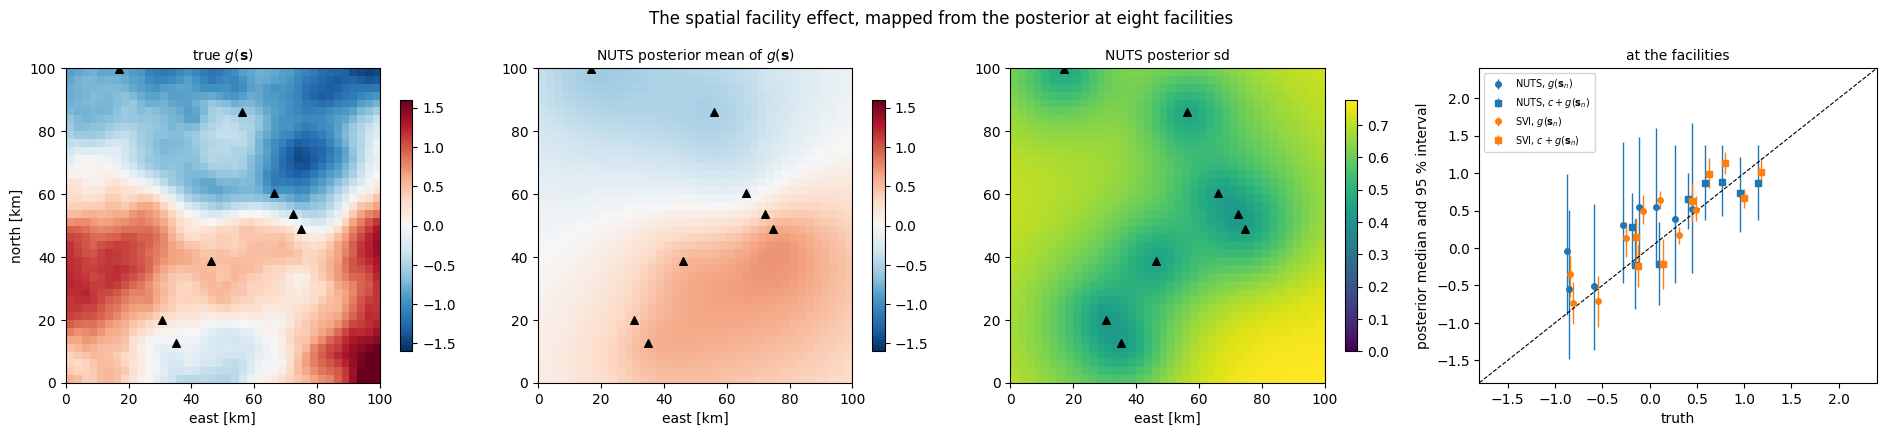

In [15]:
nuts_map_mean, nuts_map_var = map_maps["NUTS"]


def as_image(values):
    """(M,) map cells → (N_SIDE, N_SIDE) image, north up."""
    return np.asarray(einx.id("(j i) -> j i", values, i=N_SIDE))


fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
images = (
    (g_map_true, r"true $g(\mathbf{s})$", "RdBu_r", (-1.6, 1.6)),
    (nuts_map_mean, r"NUTS posterior mean of $g(\mathbf{s})$", "RdBu_r", (-1.6, 1.6)),
    (jnp.sqrt(nuts_map_var), "NUTS posterior sd", "viridis", (0.0, None)),
)
for ax, (values, title, cmap, (vmin, vmax)) in zip(axes[:3], images, strict=True):
    im = ax.imshow(
        as_image(values),
        origin="lower",
        extent=(0, BASIN_KM, 0, BASIN_KM),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.scatter(coords[:, 0], coords[:, 1], c="k", s=30, marker="^")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("east [km]")
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("north [km]")

ax = axes[3]
for samples, label, color, offset in (
    (nuts_samples, "NUTS", "C0", -0.02),
    (svi_samples, "SVI", "C1", 0.02),
):
    effect_draws = np.asarray(samples["facility_effect"])  # → (N_E, N_Ω)
    # c⁽ᵉ⁾ + g⁽ᵉ⁾(s_n)
    baseline_draws = np.asarray(  # → (N_E, N_Ω)
        einx.add(
            "member, member n -> member n",
            samples["intercept"],
            samples["facility_effect"],
        )
    )
    for draws_n, truth_n, marker, name in (
        (effect_draws, g_true, "o", r"$g(\mathbf{s}_n)$"),
        (baseline_draws, baseline_true, "s", r"$c + g(\mathbf{s}_n)$"),
    ):
        lo, mid, hi = np.percentile(draws_n, [2.5, 50, 97.5], axis=0)
        ax.errorbar(
            np.asarray(truth_n) + offset,
            mid,
            yerr=[mid - lo, hi - mid],
            fmt=marker,
            color=color,
            ms=4,
            lw=1,
            label=f"{label}, {name}",
        )
lims = (-1.8, 2.4)
ax.plot(lims, lims, "k--", lw=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("truth")
ax.set_ylabel("posterior median and 95 % interval")
ax.set_title("at the facilities", fontsize=10)
ax.legend(fontsize=7, loc="upper left")
fig.suptitle(
    "The spatial facility effect, mapped from the posterior at eight facilities"
)
plt.tight_layout()
plt.show()

The posterior mean recovers the large-scale pattern of the field, low in the north and high in the south, but not its detail, and it relaxes to zero away from the facilities, where its standard deviation grows towards the prior spread. In numbers, the NUTS posterior mean is 0.58 RMSE from the true field over the whole map, against a spread of the true field of 0.72. Within 15 km of a facility it is 0.47 (spread 0.58) and beyond 15 km 0.63 (spread 0.77), so eight facilities inform the field only near themselves. The NUTS bands are honest about this, with 98.6 % of the cells inside $\pm 2\sigma$, while the SVI bands hold only 83.6 % of the cells within 15 km of a facility.

The last panel shows why the intercept was uncertain. At the facilities the mean NUTS posterior standard deviation of $g(\mathbf{s}_n)$ is 0.46, but that of the baseline $c + g(\mathbf{s}_n)$ is 0.26: the data fix each facility's baseline rate much better than they fix how it splits into an intercept and a spatial effect. The SVI standard deviations (0.11 and 0.12) are too small for both, and miss the trade-off between the two.

## 8. Cost: the whitened path against the dense one

`markov_gp_innovations_sample` and `markov_gp_sample` give the paths the same prior. The dense one registers $\mathbf{f}_n \sim \mathcal{N}(\mathbf{0}, \mathbf{K}_{tt})$ as one `MultivariateNormal` site, batched over the facility plate. So every log-density evaluation builds the $T \times T$ kernel matrix $\mathbf{K}_{tt}$ (one matrix exponential per pair of days, $\mathcal{O}(T^2 D_x^3)$) and its Cholesky factor ($\mathcal{O}(T^3)$), and NUTS samples the paths in the centred form. The whitened one runs one scan of $T$ steps per facility. We compare them in two ways. First, we time one jitted log joint density and its gradient for the full model (all eight facilities, the same priors), with every sample site at its prior median, for records of 30 to 240 days. Then we run NUTS on both versions of the model for the first 20 days of the record, one chain of 60 draws after 60 warm-up steps each, and count the leapfrog steps per draw. We use only 20 days because the dense gradient grows so quickly with $T$ (the first table below) that a dense fit of the full record does not fit in this notebook's time budget.

In [16]:
def time_grad(sample_path, path_site, path_shape, n_days, repeats=10):
    # Shapes: N_Ω = 8 facilities; n_days days; D_x = 2
    days_n = jnp.arange(n_days, dtype=jnp.float64)  # → (n_days,)
    # counts drawn at two events per day (only the timing matters here)
    counts_n = jr.poisson(jr.PRNGKey(0), 2.0, (N_FACILITIES, n_days))  # → (N_Ω, n_days)
    mask_n = jnp.ones((N_FACILITIES, n_days), dtype=bool)  # → (N_Ω, n_days)
    model = partial(emissions_model, sample_path=sample_path)
    # every sample site at its prior median, the paths at zero
    params = {
        "intercept": jnp.asarray(0.0),
        "spatial.variance": jnp.asarray(0.5),
        "spatial.lengthscale": jnp.asarray(30.0),
        "facility_effect_u": jnp.zeros(N_FACILITIES),
        "temporal_variance": jnp.asarray(0.5),
        "temporal_lengthscale": jnp.asarray(7.0),
        path_site: jnp.zeros((N_FACILITIES, n_days, *path_shape)),
    }

    def log_joint(values):
        # today (numpyro)
        # log p(θ, z_g, Z, Y) at the given sample values
        log_p, _ = log_density(model, (coords, days_n, counts_n, mask_n), {}, values)
        return log_p

    # today (jax)
    # the log joint and its gradient, jitted once
    loss_and_grad = jax.jit(jax.value_and_grad(log_joint))
    jax.block_until_ready(loss_and_grad(params))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(loss_and_grad(params))
    return (time.perf_counter() - t0) / repeats


print(f"{'T days':>7}{'whitened, ms':>15}{'dense, ms':>12}{'dense / whitened':>19}")
for n_days in (30, 60, 120, 240):
    whitened_ms = 1e3 * time_grad(
        markov_gp_innovations_sample, "path_eps", (2,), n_days
    )
    dense_ms = 1e3 * time_grad(markov_gp_sample, "path", (), n_days)
    print(
        f"{n_days:>7}{whitened_ms:>15.2f}{dense_ms:>12.2f}"
        f"{dense_ms / whitened_ms:>19.1f}"
    )

 T days   whitened, ms   dense, ms   dense / whitened


     30           0.67        2.91                4.3


     60           0.93       39.06               41.9


    120           2.05      119.12               58.2


    240           3.33      306.83               92.0


One log density and its gradient cost 0.67 ms at 30 days and 3.33 ms at 240 days with the whitened paths, so eight times the days cost five times as much. With the dense paths they cost 2.91 ms at 30 days and 306.83 ms at 240 days, 105 times as much, and at 240 days the dense gradient is 92.0 times the whitened one. The dense path pays for $T^2$ matrix exponentials and an $\mathcal{O}(T^3)$ Cholesky factor on every evaluation, while the whitened one pays for $T$ steps of a scan.

In [17]:
# Shapes: N_Ω = 8 facilities; T_short = 20 days; 1 chain × 60 draws per version

SHORT = 20
short_args = (coords, days[:SHORT], counts[:, :SHORT], mask[:, :SHORT])
short_runs = {}
for label, sample_path in (
    ("whitened", markov_gp_innovations_sample),
    ("dense", markov_gp_sample),
):
    # today (numpyro)
    short_nuts = MCMC(
        NUTS(
            partial(emissions_model, sample_path=sample_path),
            init_strategy=init_to_median,
        ),
        num_warmup=60,
        num_samples=60,
        num_chains=1,
        progress_bar=False,
    )
    t0 = time.perf_counter()
    # today (numpyro)
    short_nuts.run(jr.PRNGKey(7), *short_args, extra_fields=("num_steps",))
    jax.block_until_ready(short_nuts.get_samples())
    seconds = time.perf_counter() - t0
    fields = short_nuts.get_extra_fields()
    short_runs[label] = (
        seconds,
        float(fields["num_steps"].mean()),
        int(fields["diverging"].sum()),
    )
print(f"{'path':<10}{'NUTS wall-clock':>17}{'steps per draw':>16}{'divergences':>13}")
for label, (seconds, steps, divergences) in short_runs.items():
    print(f"{label:<10}{seconds:>15.1f} s{steps:>16.1f}{divergences:>13}")
print()
print(
    f"full NUTS fit : {nuts_seconds:6.1f} s  "
    f"(2 chains x 300 iterations, {n_grad / 300:.1f} leapfrog steps per draw)"
)
print(f"SVI           : {svi_seconds:6.1f} s  (3000 steps x 2 particles)")
print(f"maps          : {map_seconds:6.1f} s  (2 x {N_DRAWS} draws x {n_cells} cells)")

path        NUTS wall-clock  steps per draw  divergences
whitened             19.2 s            49.6            2
dense                35.5 s           151.5            0

full NUTS fit :   83.4 s  (2 chains x 300 iterations, 63.0 leapfrog steps per draw)
SVI           :   14.7 s  (3000 steps x 2 particles)
maps          :    1.8 s  (2 x 100 draws x 1600 cells)


On the first 20 days the dense gradient is still cheap, but NUTS needed 151.5 leapfrog steps per draw with the dense, centred paths against 49.6 with the whitened ones, three times as many. The dense run took 35.5 s and the whitened one 19.2 s, both including JIT compilation, and the whitened run had two divergences in its 60 draws. So the whitened path saves twice: each gradient is cheaper, and its non-centred geometry needs fewer of them. On the full 80-day record the fit took 83.4 s of NUTS, 14.7 s of SVI and 1.8 s for the two maps, all on CPU.

## Summary

- A spatio-temporal Poisson model is a plain NumPyro function that composes a `pyrox_gp` Matérn kernel over the facility coordinates (its priors set with `set_prior`, its values drawn with the whitened `gp_sample`) with one `pyrox_ssm` Markov-GP path per facility, drawn by `markov_gp_innovations_sample` under a `numpyro.plate`. The two packages never import each other; the user composes them through NumPyro's sites.
- The trace holds the five hyperparameters, the whitened spatial values `"facility_effect_u"`, the innovations `"path_eps"` with one $(T, D_x)$ block per facility, and the deterministic `"facility_effect"`, `"path"` and `"rate"`. So the posterior draws, from NUTS or from `Predictive` with a guide, carry the rates on every day, and the withheld days and the forecast need no extra step.
- NUTS recovers all five hyperparameters within their 90 % intervals, in 83.4 s with 63 leapfrog steps per draw. Mean-field SVI took 14.7 s and gets the rates on the observed days right (97.1 % coverage), but not the hyperparameters: its temporal kernel is far too small and short, and in the forecast its band holds the true rate on only 63.3 % of the facility days, against 85.0 % for NUTS.
- Conditioning the spatial GP of each draw on its values at the facilities maps the facility effect, with bands that say how little eight facilities tell about the field away from themselves (98.6 % of the map cells inside $\pm 2\sigma$ for NUTS).
- Per gradient, the whitened path cost 0.67 to 3.33 ms for records of 30 to 240 days and the dense `markov_gp_sample` 2.91 to 306.83 ms. On the first 20 days NUTS needed 49.6 leapfrog steps per draw with the whitened paths against 151.5 with the dense, centred ones.

For the plate over sites and the non-centred draws see [Example 2](ssm_hierarchical_sites.ipynb), for a shared signal that couples the sites [Example 3](ssm_shared_plus_site.ipynb), and for the Matérn SDE and the Kalman filter [Example 1](ssm_one_site.ipynb).